Model: /mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/runs/lateral_flow/yolo26n_full/weights/best.pt
Images: /mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick
GPU: 0
/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/N_Picture2.png: 1 windows detected


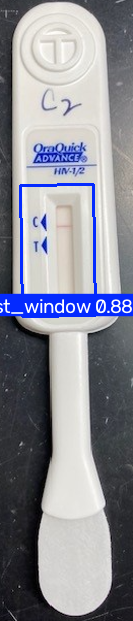

/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/N_Picture20.png: 1 windows detected


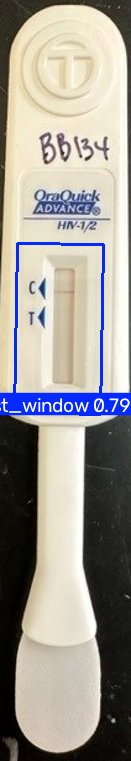

/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/N_Picture21.png: 1 windows detected


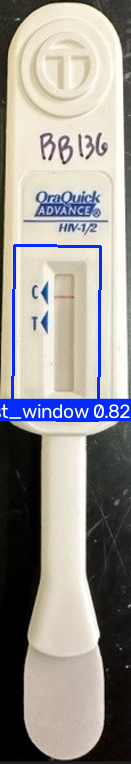

/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/N_Picture22.png: 1 windows detected


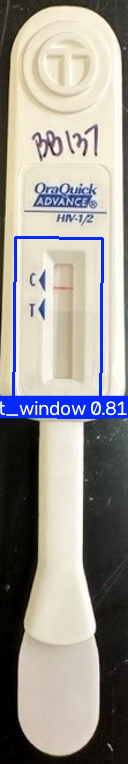

/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/N_Picture23.png: 1 windows detected


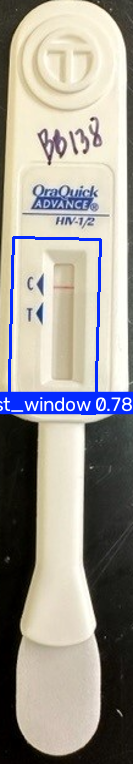

/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/N_Picture24.png: 1 windows detected


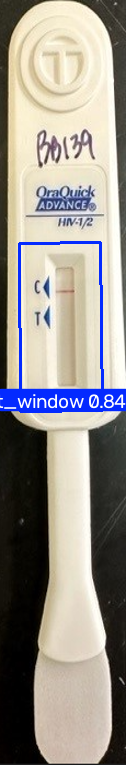

/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/P_Picture1.png: 1 windows detected
/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/P_Picture10.png: 1 windows detected
/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/P_Picture11.png: 1 windows detected
/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/P_Picture12.png: 1 windows detected
/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/P_Picture13.png: 1 windows detected
/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/P_Picture14.png: 1 windows detected
/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/P_Picture15.png: 1 windows detected
/mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/data/lateral_flow/independent_alloraquick/P_Picture16.png: 1 windows detected
/mnt/bst/dgx/atom

In [1]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image
from IPython.display import display
import torch

PROJECT = Path.home() / "projects" / "YOLO"

# Your trained lateral-flow model
MODEL_PATH = (
    PROJECT / "runs/lateral_flow/yolo26n_full/weights/best.pt"
)

# New independent test images
IMAGE_DIR = (
    PROJECT / "data/lateral_flow/independent_alloraquick"
)

# Prediction results
OUTPUT_DIR = (
    PROJECT / "runs/notebook_predictions/yolo26n_obb/AllOraQick"
)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Model:", MODEL_PATH)
print("Images:", IMAGE_DIR)
print("GPU:", DEVICE)

assert MODEL_PATH.is_file(), "Model not found"
assert IMAGE_DIR.is_dir(), "Image directory not found"

model = YOLO(str(MODEL_PATH))

results = model.predict(
    source=str(IMAGE_DIR),
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(OUTPUT_DIR.parent),
    name=OUTPUT_DIR.name,
    exist_ok=True,
    stream=True,
    verbose=False
)

image_count = 0
detection_count = 0

for result in results:
    image_count += 1

    n = len(result.obb) if result.obb is not None else 0
    detection_count += n

    print(f"{result.path}: {n} windows detected")

    # Display first 6 annotated images in Jupyter
    if image_count <= 6:
        annotated = Image.fromarray(
            result.plot()[..., ::-1]
        )
        display(annotated)

print("\nPrediction completed")
print("Images processed:", image_count)
print("Total detected windows:", detection_count)
print("Results saved:", OUTPUT_DIR)

Total annotated images: 22


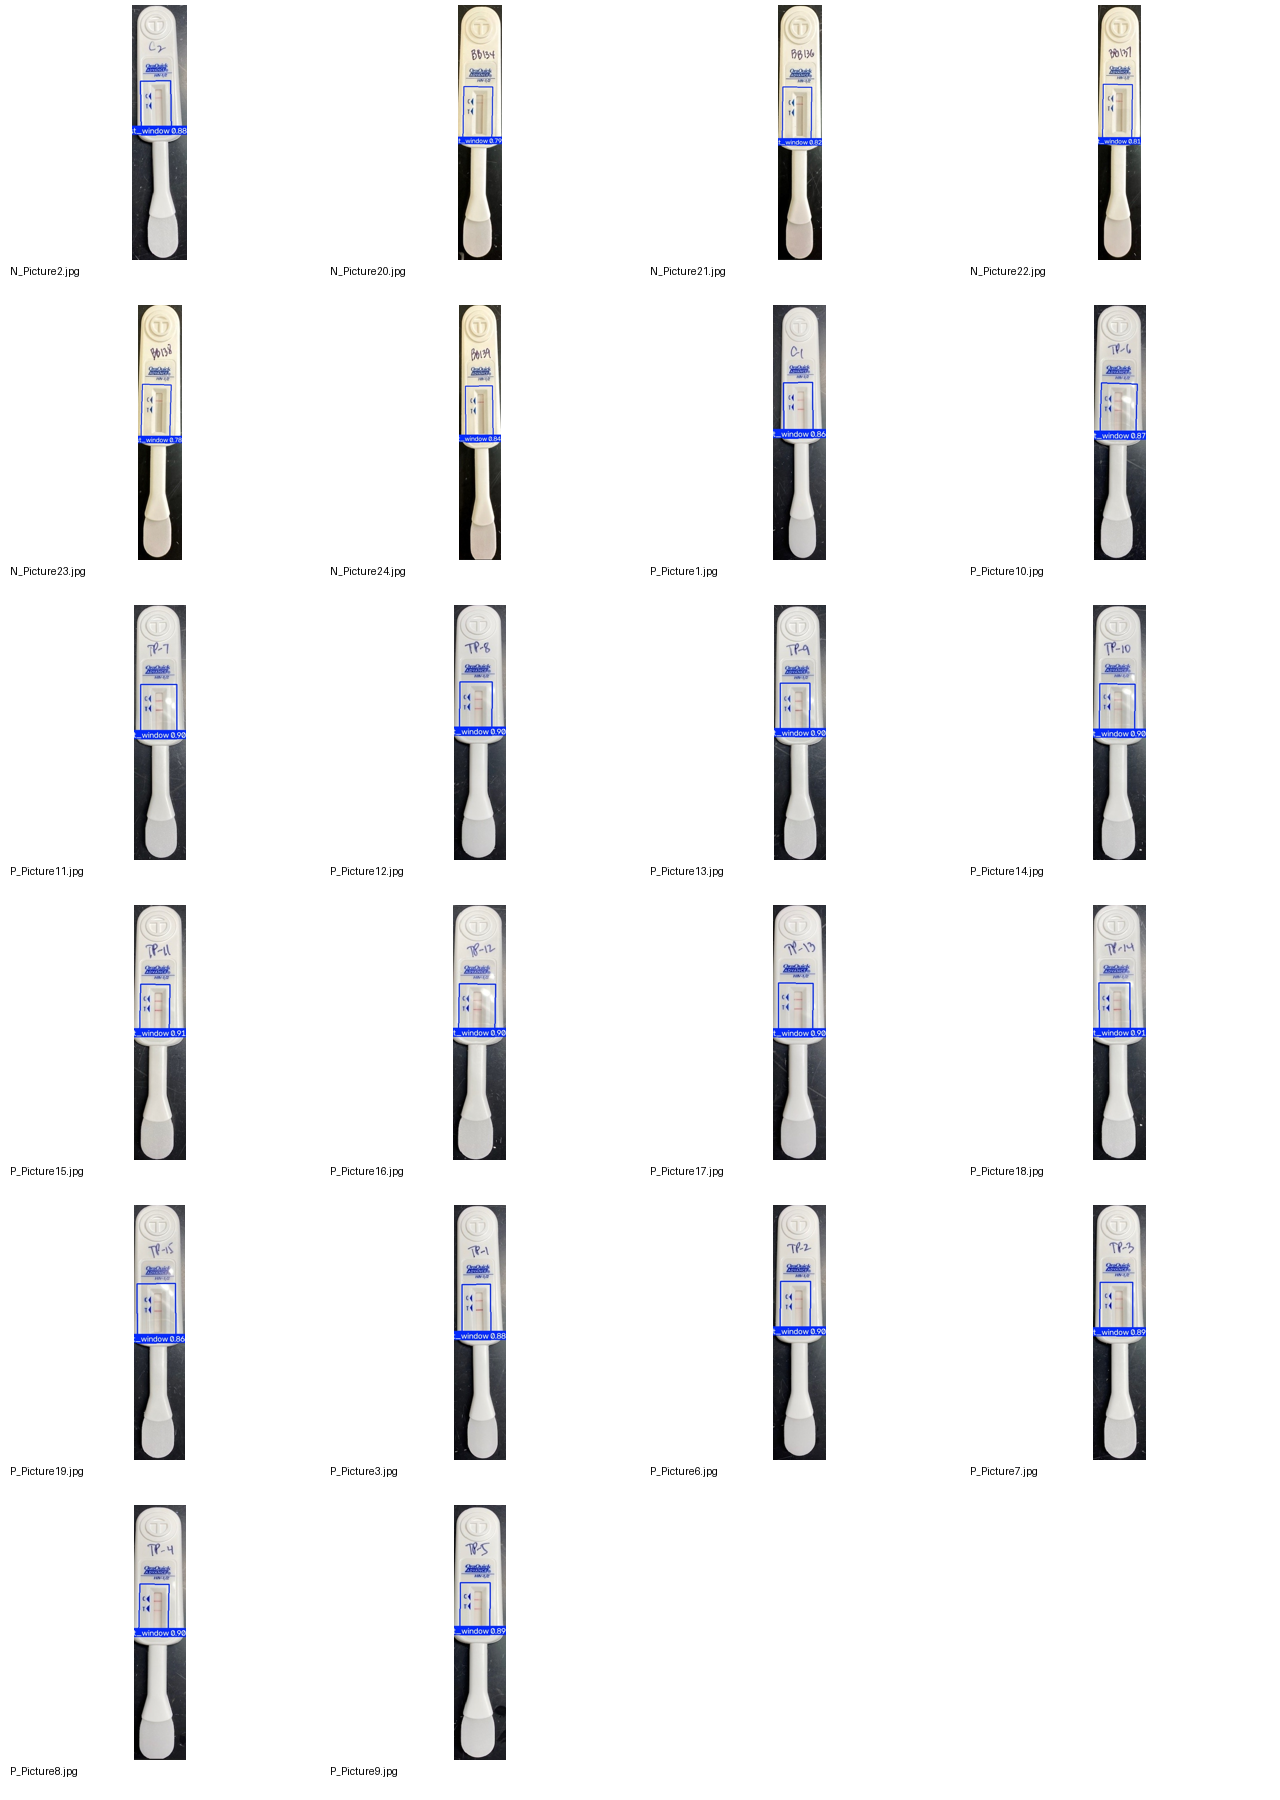

Saved contact sheet: /mnt/bst/dgx/atomitak/aadhika2/projects/YOLO/runs/notebook_predictions/yolo26n_obb/AllOraQick/AllOraQick_contact_sheet.jpg


In [3]:
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
import math

# Folder containing YOLO annotated images
image_dir = OUTPUT_DIR

# Collect all predicted images
images = sorted([
    p for p in image_dir.iterdir()
    if p.suffix.lower() in (".png", ".jpg", ".jpeg")
    and p.name != "AllOraQick_contact_sheet.jpg"
])

print("Total annotated images:", len(images))

if images:
    # Contact sheet layout
    columns = 4
    cell_width = 320
    cell_height = 300
    rows = math.ceil(len(images) / columns)

    sheet = Image.new(
        "RGB",
        (columns * cell_width, rows * cell_height),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    for i, path in enumerate(images):
        with Image.open(path) as img:
            thumb = ImageOps.contain(
                img.convert("RGB"),
                (300, 255)
            )

        x = (i % columns) * cell_width
        y = (i // columns) * cell_height

        # Center the image
        px = x + (cell_width - thumb.width) // 2
        py = y + 5

        sheet.paste(thumb, (px, py))

        # Image filename
        draw.text(
            (x + 10, y + 265),
            path.name,
            fill="black"
        )

    # Save combined image
    output = image_dir / "AllOraQick_contact_sheet.jpg"
    sheet.save(output, quality=95)

    # Display all images together
    display(sheet)

    print("Saved contact sheet:", output)

else:
    print("No annotated images found.")